# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.4. Regresión logística y árbol de decisión

*Bienvenidos* a este jupyter notebook que nos será de utilidad para predecir la especie de una flor (clasificación) y aprender a seleccionar la configuración de dos modelos mediante GridSearchCV y validación cruzada.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Importación de bibliotecas

In [1]:
import warnings
# Ignorar todos los warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

#### Carga de los datos

In [2]:
#Cargar la base de datos
df = pd.read_csv('data_Iris.csv') 

#Mostrar 5 filas de datos al azar
df.sample(5, random_state=42)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
73,6.1,2.8,4.7,1.2,versicolor
18,5.7,3.8,1.7,0.3,setosa
118,7.7,2.6,6.9,2.3,virginica
78,6.0,2.9,4.5,1.5,versicolor
76,6.8,2.8,4.8,1.4,versicolor


In [3]:
print("Dimensiones (filas, columnas):", df.shape)

Dimensiones (filas, columnas): (150, 5)


In [4]:
print("Datos faltantes:", df.isna().sum().sum())

Datos faltantes: 0


In [5]:
df["Species"].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

#### Separar las entradas y la respuesta

In [6]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, stratify=df.Species ,train_size = 0.7, random_state=42)

X_train = train.drop('Species', axis = 1)
Y_train = train.Species
X_test = test.drop('Species', axis = 1)
Y_test = test.Species

# Imprime dimensiones de datos de entrenamiento
print("Train:", train.shape)
# Imprime dimensiones de datos de prueba
print("Test:",test.shape)

total_observations = train.shape[0] + test.shape[0]
print("Total de observaciones en ambos conjuntos:", total_observations)
print("Observaciones originales en el DataFrame:", df.shape[0])

Train: (105, 5)
Test: (45, 5)
Total de observaciones en ambos conjuntos: 150
Observaciones originales en el DataFrame: 150


In [7]:
pd.DataFrame({
    "Entrenamiento": Y_train.value_counts(),
    "Prueba": Y_test.value_counts()})

,Entrenamiento,Prueba
Species,,
setosa,35,15
versicolor,35,15
virginica,35,15


#### Árbol de Decisión

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': np.arange(3, 15), # Values from 3 to 14
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Decision Tree model
dtree_model = DecisionTreeClassifier(random_state=42)

# Use GridSearchCV to test all combinations with 5-fold cross-validation (cv=5)
grid_search = GridSearchCV(
    estimator=dtree_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy', # Or another appropriate metric
    verbose=1,
    n_jobs=-1 # Use all available cores
)

# Fit the GridSearchCV to the data
grid_search.fit(X_train,Y_train)

print ("Mean cross-validated score of the best_estimator: {}".format (grid_search.best_score_))
print ("best parameters: {}".format (grid_search.best_params_))
print ("best estimator: {}".format (grid_search.best_estimator_))

best = grid_search.best_estimator_  
y1 = best.predict(X_test)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Mean cross-validated score of the best_estimator: 0.9523809523809523
best parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
best estimator: DecisionTreeClassifier(max_depth=3, random_state=42)


In [9]:
model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train,Y_train)

y2 = model.predict(X_test)
print(np.array_equal(y1, y2))  # True esperado

True


In [10]:
# Scikit learn modules for Model Evaluation & Improvement
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, precision_recall_curve
from sklearn.metrics import auc, roc_auc_score, roc_curve

In [11]:
acc = accuracy_score(Y_test, y2)
prec = precision_score(Y_test, y2, average='macro')     # o 'weighted'
rec  = recall_score(Y_test, y2, average='macro')        # o 'weighted'
f1   = f1_score(Y_test, y2, average='macro')            # o 'weighted'

print("Accuracy:", np.round(acc,2))
print("Precision:", np.round(prec,2))
print("Recall:", np.round(rec,2))
print("F1-score:", np.round(f1,2))

Accuracy: 0.98
Precision: 0.98
Recall: 0.98
F1-score: 0.98


In [12]:
print(classification_report(Y_test, y2))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



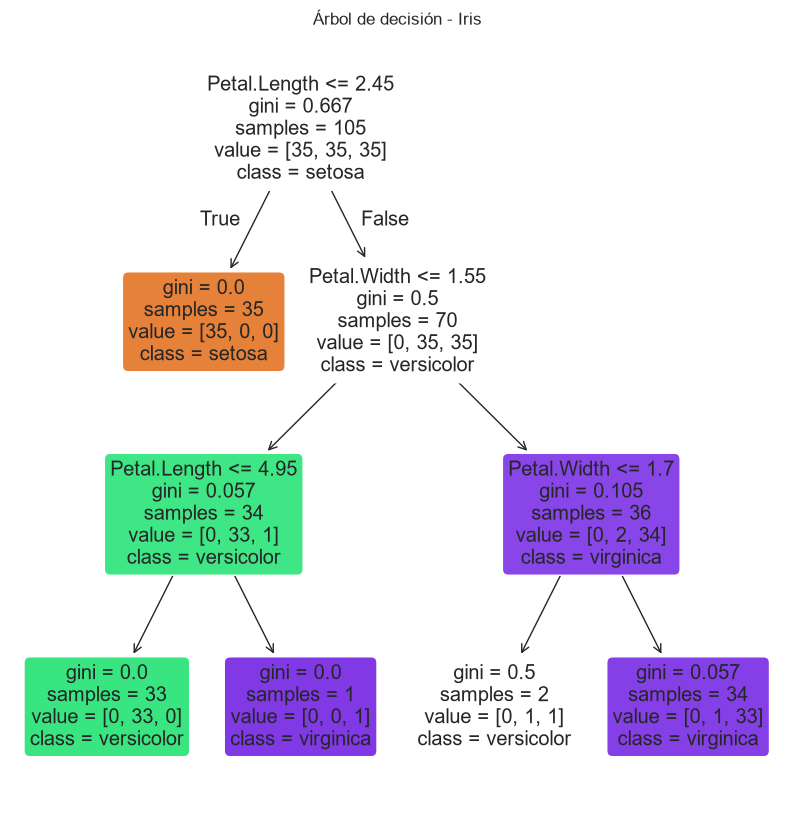

In [13]:
from sklearn.tree import  plot_tree

plt.figure(figsize=(10, 10))
plot_tree(
    model,
    feature_names=X_train.columns,              # ['Sepal.Length', 'Sepal.Width', ...]
    class_names=sorted(Y_train.unique()),       # ['setosa', 'versicolor', 'virginica']
    filled=True,
    rounded=True
)
plt.title("Árbol de decisión - Iris")
plt.show()


#### Regresión Logística

In [14]:
# Búsqueda Hiperparámetros
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = [
    # Solvers generales (multiclase) con l2/none
    {'solver': ['lbfgs', 'newton-cg', 'sag'],
     'penalty': ['l2', 'none'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    # liblinear (binario), l1 o l2
    {'solver': ['liblinear'],
     'penalty': ['l1', 'l2'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    # saga: l1, l2, elasticnet (requiere l1_ratio)
    {'solver': ['saga'],
     'penalty': ['l1', 'l2'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    {'solver': ['saga'],
     'penalty': ['elasticnet'],
     'l1_ratio': [0.2, 0.5, 0.8],
     'C': [1.0, 0.1],
     'max_iter': [1000, 2000]},
]



grid_search = GridSearchCV(LogisticRegression(random_state=42, class_weight="balanced"), param_grid = param_grid, scoring='accuracy', cv=5, refit=True)
grid_search.fit(X_train,Y_train)

print ("Mean cross-validated score of the best_estimator: {}".format (grid_search.best_score_))
print ("best parameters: {}".format (grid_search.best_params_))
print ("best estimator: {}".format (grid_search.best_estimator_))

best = grid_search.best_estimator_  
y1 = best.predict(X_test)

Mean cross-validated score of the best_estimator: 0.980952380952381
best parameters: {'C': 100, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'lbfgs'}
best estimator: LogisticRegression(C=100, class_weight='balanced', max_iter=1000, penalty='l2',
                   random_state=42)


In [15]:
model = LogisticRegression(C=100, class_weight='balanced', max_iter=1000,
                   random_state=42).fit(X_train,Y_train)

y2 = model.predict(X_test)
print(np.array_equal(y1, y2))  # True esperado

True


In [16]:
acc = accuracy_score(Y_test, y2)
prec = precision_score(Y_test, y2, average='macro')     # o 'weighted'
rec  = recall_score(Y_test, y2, average='macro')        # o 'weighted'
f1   = f1_score(Y_test, y2, average='macro')            # o 'weighted'

print("Accuracy:", np.round(acc,2))
print("Precision:", np.round(prec,2))
print("Recall:", np.round(rec,2))
print("F1-score:", np.round(f1,2))

Accuracy: 0.93
Precision: 0.94
Recall: 0.93
F1-score: 0.93


In [17]:
print(classification_report(Y_test, y2))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.83      1.00      0.91        15
   virginica       1.00      0.80      0.89        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45

